# House Price Prediction using Linear Regression
**Project Code:** KZ-ML-01 &nbsp;|&nbsp; **Category:** Machine Learning Web Application

This notebook covers the full training pipeline described in the capstone spec:
data preprocessing, exploratory data analysis, model training (Linear Regression
vs Decision Tree Regressor), evaluation, and saving the best model for the Flask
web application.


## 1. Imports

In [1]:
import json
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

sys.path.append("..")  # project root, for the custom DecisionTreeRegressor below
from decision_tree import SimpleDecisionTreeRegressor as DecisionTreeRegressor

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42


> **Note on the Decision Tree implementation:** this project uses a small
> from-scratch CART regression tree (`decision_tree.py`, project root)
> instead of `sklearn.tree.DecisionTreeRegressor`. On this machine,
> scikit-learn's compiled tree extension is blocked by an Application
> Control / WDAC policy (`sklearn.neighbors._quad_tree` fails to load). The
> custom class exposes the same `fit`/`predict` API and uses the same
> variance-reduction (SSE) splitting criterion, so the comparison below is
> unaffected. On a machine without that restriction, swapping back to
> `from sklearn.tree import DecisionTreeRegressor` works identically.


## 2. Load Dataset
Dataset: *Housing Prices Dataset* (Kaggle, uploaded by Yasser H.) — 545 rows with
`price`, `area`, `bedrooms`, `bathrooms`, `stories`, `mainroad`, `guestroom`,
`basement`, `hotwaterheating`, `airconditioning`, `parking`, `prefarea` and
`furnishingstatus`.


In [2]:
df = pd.read_csv("../data/Housing.csv")
print(df.shape)
df.head()


(545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,12030000,9846,4,4,2,yes,no,no,no,no,2,no,semi-furnished
1,9947000,8125,4,3,2,yes,no,no,yes,yes,2,no,semi-furnished
2,9892000,5919,3,1,4,yes,no,yes,no,yes,1,no,furnished
3,9876000,5373,5,4,2,yes,no,yes,no,no,0,yes,furnished
4,9828000,8372,3,3,3,yes,no,no,no,no,0,no,unfurnished


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB


In [4]:
df.describe()


,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,6.632171e+06,4881.222018,3.264220,1.484404,2.009174,1.075229
std,1.338827e+06,1569.345904,1.007283,0.732790,0.980466,0.937295
min,3.175000e+06,1810.000000,1.000000,1.000000,1.000000,0.000000
25%,5.734000e+06,3763.000000,3.000000,1.000000,1.000000,0.000000
50%,6.643000e+06,4667.000000,3.000000,1.000000,2.000000,1.000000
75%,7.470000e+06,5681.000000,4.000000,2.000000,3.000000,2.000000
max,1.203000e+07,11878.000000,6.000000,4.000000,4.000000,3.000000


## 3. Data Preprocessing
- Check for missing values and duplicate rows.
- Convert the `yes`/`no` columns to `1`/`0`.
- One-hot encode `furnishingstatus`, dropping the first category
  (`furnished`) to avoid redundant columns (the "dummy variable trap").


In [5]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())


Missing values per column:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Duplicate rows: 0


In [6]:
binary_cols = [
    "mainroad", "guestroom", "basement",
    "hotwaterheating", "airconditioning", "prefarea",
]
df_clean = df.copy()
for col in binary_cols:
    df_clean[col] = df_clean[col].map({"yes": 1, "no": 0})

df_clean = pd.get_dummies(df_clean, columns=["furnishingstatus"], drop_first=True)
# Convert the new dummy columns from bool to int (0/1) for a clean numeric frame
dummy_cols = [c for c in df_clean.columns if c.startswith("furnishingstatus_")]
df_clean[dummy_cols] = df_clean[dummy_cols].astype(int)

df_clean.head()


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,12030000,9846,4,4,2,1,0,0,0,0,2,0,1,0
1,9947000,8125,4,3,2,1,0,0,1,1,2,0,1,0
2,9892000,5919,3,1,4,1,0,1,0,1,1,0,0,0
3,9876000,5373,5,4,2,1,0,1,0,0,0,1,0,0
4,9828000,8372,3,3,3,1,0,0,0,0,0,0,0,1


## 4. Exploratory Data Analysis

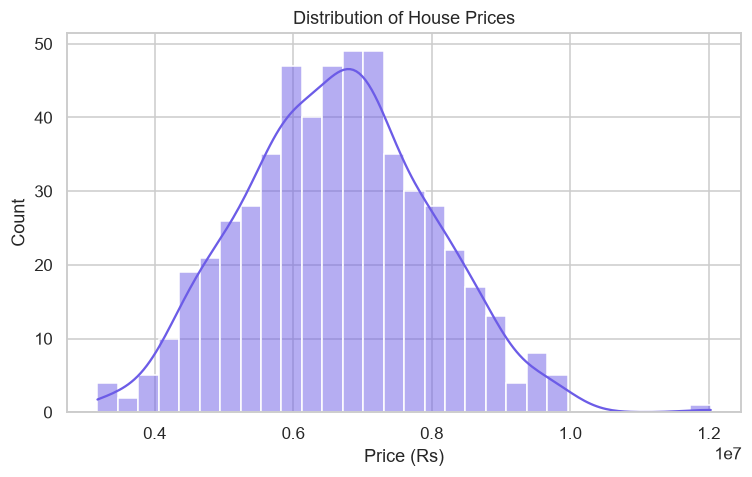

In [7]:
plt.figure(figsize=(7, 4.5))
sns.histplot(df["price"], bins=30, kde=True, color="#6c5ce7")
plt.title("Distribution of House Prices")
plt.xlabel("Price (Rs)")
plt.tight_layout()
plt.savefig("../static/images/price_distribution.png")
plt.show()


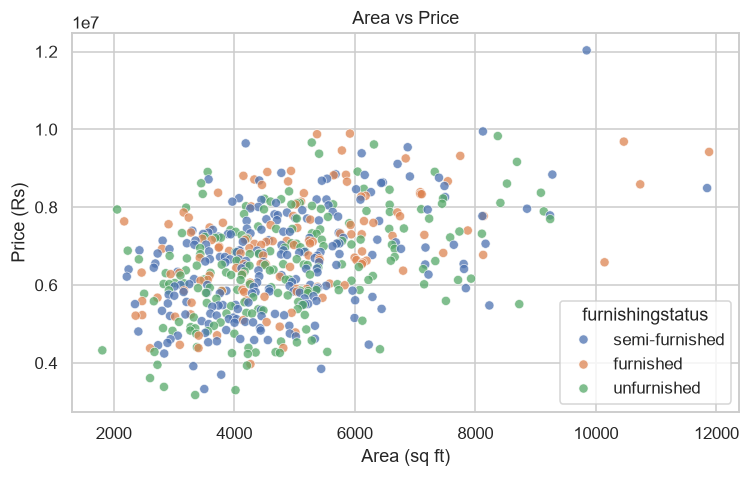

In [8]:
plt.figure(figsize=(7, 4.5))
sns.scatterplot(data=df, x="area", y="price", hue="furnishingstatus", alpha=0.75)
plt.title("Area vs Price")
plt.xlabel("Area (sq ft)")
plt.ylabel("Price (Rs)")
plt.tight_layout()
plt.savefig("../static/images/area_vs_price.png")
plt.show()


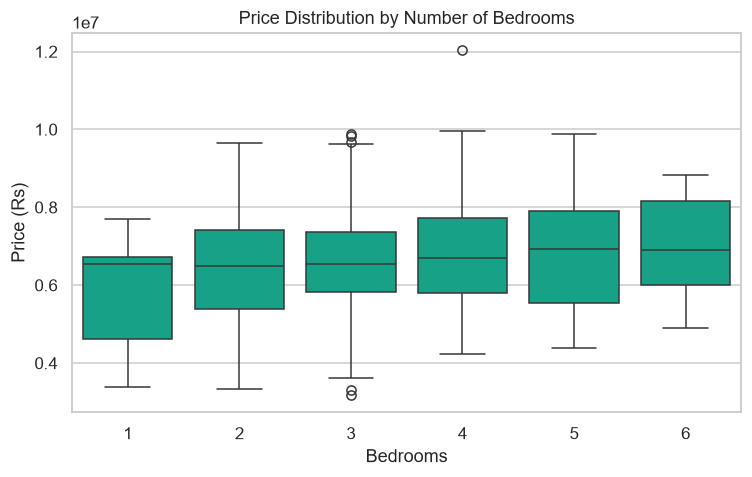

In [9]:
plt.figure(figsize=(7, 4.5))
sns.boxplot(data=df, x="bedrooms", y="price", color="#00b894")
plt.title("Price Distribution by Number of Bedrooms")
plt.xlabel("Bedrooms")
plt.ylabel("Price (Rs)")
plt.tight_layout()
plt.savefig("../static/images/bedrooms_boxplot.png")
plt.show()


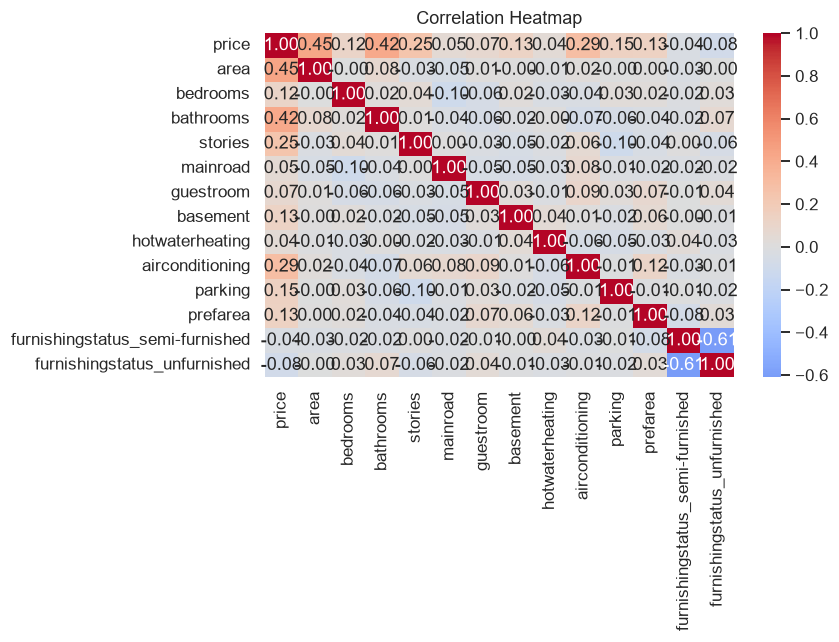

In [10]:
plt.figure(figsize=(8, 6))
corr = df_clean.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("../static/images/correlation_heatmap.png")
plt.show()


**EDA insights:**
- Price is right-skewed — most houses cluster at the lower end with a long tail of
  expensive properties.
- Area has the strongest visible positive relationship with price.
- Bathrooms and air conditioning show a noticeably positive effect on price in the
  correlation heatmap.
- Furnished houses trend toward higher prices than unfurnished ones at the same area.


## 5. Model Training
Split the data 80:20 into training and testing sets, then train a
**Linear Regression** model and a **Decision Tree Regressor** on the same split.


In [11]:
X = df_clean.drop(columns=["price"])
y = df_clean["price"]
feature_columns = X.columns.tolist()
print("Feature columns:", feature_columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print(f"Train rows: {len(X_train)}  Test rows: {len(X_test)}")


Feature columns: ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']
Train rows: 436  Test rows: 109


In [12]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

tree_reg = DecisionTreeRegressor(max_depth=5, min_samples_split=10)
tree_reg.fit(X_train.values, y_train.values)
print("Both models trained.")


Both models trained.


## 6. Model Evaluation
Compute R-squared, MAE and RMSE for both models on the held-out test set.


In [13]:
def evaluate(model, X_te, y_te):
    preds = model.predict(X_te)
    return {
        "r2": r2_score(y_te, preds),
        "mae": mean_absolute_error(y_te, preds),
        "rmse": np.sqrt(mean_squared_error(y_te, preds)),
    }, preds

lin_metrics, lin_preds = evaluate(lin_reg, X_test, y_test)
tree_metrics, tree_preds = evaluate(tree_reg, X_test, y_test)

results = pd.DataFrame([lin_metrics, tree_metrics], index=["Linear Regression", "Decision Tree"])
results


,r2,mae,rmse
Linear Regression,0.653754,758066.485906,9.390577e+05
Decision Tree,0.413772,963666.251436,1.221894e+06


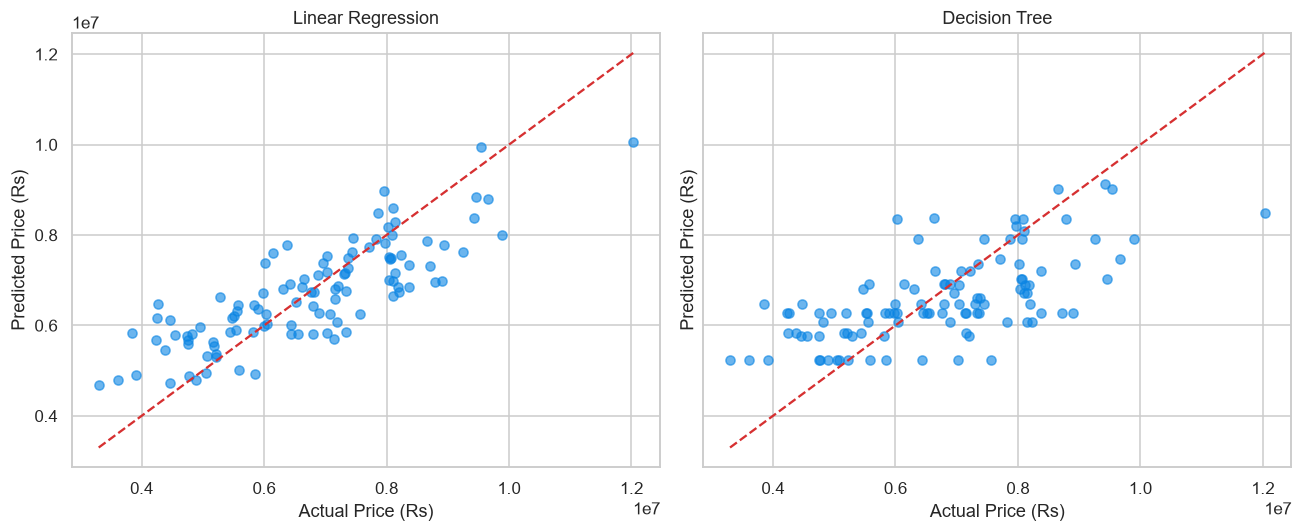

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, preds, name in zip(axes, [lin_preds, tree_preds], ["Linear Regression", "Decision Tree"]):
    ax.scatter(y_test, preds, alpha=0.6, color="#0984e3")
    lims = [y_test.min(), y_test.max()]
    ax.plot(lims, lims, "--", color="#d63031", linewidth=1.5)
    ax.set_xlabel("Actual Price (Rs)")
    ax.set_ylabel("Predicted Price (Rs)")
    ax.set_title(name)
plt.tight_layout()
plt.savefig("../static/images/actual_vs_predicted.png")
plt.show()


In [15]:
coef_table = pd.Series(lin_reg.coef_, index=feature_columns).sort_values(key=abs, ascending=False)
print("Linear Regression intercept (b0):", round(lin_reg.intercept_, 2))
print("\nCoefficients (impact on price per unit, all else equal):")
coef_table.round(2)


Linear Regression intercept (b0): 1704402.12

Coefficients (impact on price per unit, all else equal):


bathrooms                          770195.18
airconditioning                    769708.74
hotwaterheating                    429587.62
basement                           423967.96
prefarea                           388253.14
stories                            315889.56
mainroad                           309147.64
parking                            270330.32
furnishingstatus_unfurnished      -265497.07
guestroom                          226560.43
furnishingstatus_semi-furnished   -179131.92
bedrooms                           167789.36
area                                  334.34
dtype: float64

**Interpretation:** the `area` coefficient shows the change in predicted price
(in Rs) for every extra square foot, holding all other features constant.
Binary features (e.g. `airconditioning`, `prefarea`) show the Rs premium
associated with having that feature versus not having it.


## 7. Model Comparison and Saving
Pick whichever model has the better **test R-squared** and persist it with
`joblib` alongside the ordered feature-column list, so the Flask app can
reconstruct the exact same input vector at prediction time.


In [16]:
best_name = "Linear Regression" if lin_metrics["r2"] >= tree_metrics["r2"] else "Decision Tree"
best_model = lin_reg if best_name == "Linear Regression" else tree_reg
best_metrics = lin_metrics if best_name == "Linear Regression" else tree_metrics

print(f"Best model: {best_name}  (test R2 = {best_metrics['r2']:.4f})")

joblib.dump(best_model, "../model/model.pkl")
joblib.dump(feature_columns, "../model/columns.pkl")

metrics_out = {
    "best_model": best_name,
    "linear_regression": lin_metrics,
    "decision_tree": tree_metrics,
    "n_rows": int(len(df)),
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
}
with open("../model/metrics.json", "w") as f:
    json.dump(metrics_out, f, indent=2)

print("Saved model/model.pkl, model/columns.pkl and model/metrics.json")


Best model: Linear Regression  (test R2 = 0.6538)
Saved model/model.pkl, model/columns.pkl and model/metrics.json


## 8. Conclusion
Both models were trained on an 80:20 split of the 545-row housing dataset and
evaluated with R-squared, MAE and RMSE. The better-performing model on the test
set (by R-squared) is saved as `model/model.pkl` and loaded by the Flask app at
startup (`app.py`) to serve instant predictions through a web form, with every
prediction logged to a SQLite history table.
